# Project 1 — How good does the best strategy look when none of them work?

**The question.** If I try several hundred trading rules on the same five years of
data and report the best one, how impressive will it look *even if every rule
is worthless*? And once I know that, does the best rule on the real data clear
the bar?

**Why this is the right first project.** In the internship the frozen random
layer and the no-hidden-layer model were there to answer "what does *nothing*
look like on this task?" before any architecture was allowed to claim a win.
This notebook is the same control, moved to finance. The only difference is
the size of the trap: on Fashion-MNIST the noise floor was about 0.2 accuracy
points. Here the noise floor turns out to be larger than the effect being
looked for.

**Structure**

1. Data and one market return series
2. A universe of several hundred trading rules, and a backtester with no look-ahead
3. The null experiment: the same rules on data with no predictability
4. Theory: the expected maximum Sharpe ratio, and how many *independent* trials there really were
5. The real data, tested four ways (permutation test, Deflated Sharpe Ratio, Reality Check, out-of-sample)
6. Probability of Backtest Overfitting (CSCV)
7. The same disease in ML form: purged and embargoed cross-validation
8. What was found, and what this cannot tell us

In [1]:
import itertools
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import common as C

C.set_style()
ANN = np.sqrt(C.TRADING_DAYS)   # daily Sharpe -> annualised Sharpe
SEED = 0

## 1. Data

`common.py` loads daily closes for the S&P 500 constituents and neutralises
two kinds of fictitious return (unadjusted spin-offs and one-day bad ticks —
the docstrings there list every one). The raw panel's largest "moves" were all
artefacts: eBay −57% on the day PayPal was spun out, Alliant Energy −49% then
+101% on consecutive days. A backtest run on the raw file would have found
those and traded them.

For this project the panel is collapsed to **one series**: the equal-weighted
average return across all stocks each day. One series keeps the experiment
easy to reason about — every rule is a rule for timing "the market".

In [2]:
prices = C.load_prices()
stock_rets = C.clean_returns(prices)

mkt = stock_rets.mean(axis=1)          # equal-weighted market return, per day
r = mkt.to_numpy()
T_all = len(r)

print(f"\nequal-weighted market: mean {r.mean()*252:.1%}/yr, "
      f"vol {r.std(ddof=1)*ANN:.1%}/yr, Sharpe {r.mean()/r.std(ddof=1)*ANN:.2f}")
print(f"lag-1 autocorrelation of daily returns: {np.corrcoef(r[1:], r[:-1])[0,1]:+.3f}")

panel: 1258 days x 470 tickers (2013-02-11 to 2018-02-07)
neutralised 9 corporate-action days and 5 bad ticks
largest remaining one-day move: 61.9%

equal-weighted market: mean 14.0%/yr, vol 12.7%/yr, Sharpe 1.10
lag-1 autocorrelation of daily returns: -0.003


Two things to notice before building anything.

**The market went up, a lot.** A Sharpe above 1 for buy-and-hold means *any*
rule that happens to be long most of the time will look good, for a reason
that has nothing to do with timing. To stop that contaminating everything
downstream, every backtest below is run on **demeaned** returns
$x_t = r_t - \bar r$. On demeaned returns "always long" earns exactly zero, so
whatever a rule earns is timing skill (or luck) and nothing else. This is the
equivalent of reading every accuracy against the linear floor rather than
against the frozen layer.

**Survivorship bias.** The ticker list is index membership as of 2018, so
failed companies are missing. Demeaning removes the inflated average return
but not subtler effects. It goes in the limitations.

## 2. A universe of trading rules

Each rule turns the price history up to day $t$ into a position in
$\{-1, 0, +1\}$ (short, flat, long). Six families, each with a parameter grid:

| family | idea | parameters |
|---|---|---|
| `ma` | moving-average crossover: long when the fast average is above the slow one | fast, slow window |
| `mom` | time-series momentum: sign of the past return | lookback, days skipped |
| `zrev` | mean reversion: fade the price when it is far from its rolling mean | window, z-score threshold |
| `brk` | channel breakout: long after a new N-day high, short after a new low | window |
| `vol` | volatility regime: long when recent volatility is below its longer-run average | short, long window |
| `dow` | calendar: long on one weekday, flat otherwise | weekday |

Every rule is also included **mirrored** (positions multiplied by −1), because
a researcher who finds that a rule loses money will simply trade the opposite.
That is a real doubling of the search and it has to be counted.

The helpers first. They are all "rolling window" statistics written with
cumulative sums so they stay fast when called thousands of times.

In [3]:
def rolling_mean(x, w):
    """Mean of the last w values, ending at each index. NaN until w values exist.

    cumsum trick: sum(x[i-w+1 : i+1]) = c[i+1] - c[i+1-w], one subtraction per
    element instead of a Python loop.
    """
    c = np.cumsum(np.insert(x, 0, 0.0))
    out = np.full(len(x), np.nan)
    out[w - 1:] = (c[w:] - c[:-w]) / w
    return out


def rolling_std(x, w):
    """Rolling standard deviation via E[x^2] - E[x]^2 (clipped at 0 for rounding)."""
    m, m2 = rolling_mean(x, w), rolling_mean(x * x, w)
    return np.sqrt(np.maximum(m2 - m * m, 0.0))

Now the signal generator. It takes a return series and gives back a
`(days × rules)` matrix of *desired* positions plus a label for each column.

One convention matters: `signals[t]` may use information up to and including
the close of day `t`. It is **not** yet the position that earns day `t`'s
return — that shift happens in the backtester, in exactly one place, so it
cannot be forgotten in one family and applied in another.

In [4]:
MA_FAST = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50, 60]
MA_SLOW = [5, 10, 15, 20, 30, 40, 50, 60, 80, 100, 120, 150, 200, 250]
MOM_LB = [1, 2, 3, 4, 5, 7, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100, 120,
          150, 200, 250]
MOM_SKIP = [0, 1, 2, 5]
Z_WIN = [5, 10, 15, 20, 30, 40, 60, 80, 100, 120, 150, 200]
Z_THR = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]
BRK_WIN = [5, 10, 15, 20, 30, 40, 50, 60, 80, 100, 120, 150, 200, 250]
VOL_SHORT = [5, 10, 20, 40, 60, 120]
VOL_LONG = [60, 120, 250]
BURN_IN = 250          # longest lookback: nothing is scored before this day


def make_signals(ret, weekday=None):
    """All rules for one return series -> (signals[T, N], labels[N])."""
    n = len(ret)
    logp = np.cumsum(np.log1p(ret))        # log price path, starting at 0
    cols, labels = [], []

    # --- moving-average crossover -------------------------------------------
    ma = {w: rolling_mean(logp, w) for w in set(MA_FAST) | set(MA_SLOW)}
    for f, s in itertools.product(MA_FAST, MA_SLOW):
        if s <= f:
            continue
        cols.append(np.sign(ma[f] - ma[s]))
        labels.append(("ma", f, s))

    # --- time-series momentum ----------------------------------------------
    # return over `lb` days, measured up to `skip` days ago
    for lb, skip in itertools.product(MOM_LB, MOM_SKIP):
        past = np.full(n, np.nan)
        end = logp[: n - skip] if skip else logp          # price `skip` days ago
        past[lb + skip:] = end[lb:] - end[:-lb]
        cols.append(np.sign(past))
        labels.append(("mom", lb, skip))

    # --- z-score mean reversion --------------------------------------------
    for w in Z_WIN:
        z = (logp - rolling_mean(logp, w)) / (rolling_std(logp, w) + 1e-12)
        for thr in Z_THR:
            sig = np.where(z > thr, -1.0, np.where(z < -thr, 1.0, 0.0))
            sig[np.isnan(z)] = np.nan
            cols.append(sig)
            labels.append(("zrev", w, thr))

    # --- channel breakout ---------------------------------------------------
    # go long at a new w-day high, short at a new w-day low, and HOLD until
    # the opposite event (that is what the forward-fill does)
    p = pd.Series(logp)
    for w in BRK_WIN:
        hi, lo = p.rolling(w).max().to_numpy(), p.rolling(w).min().to_numpy()
        event = np.where(logp >= hi, 1.0, np.where(logp <= lo, -1.0, np.nan))
        sig = pd.Series(event).ffill().to_numpy(copy=True)
        sig[:w] = np.nan
        cols.append(sig)
        labels.append(("brk", w, 0))

    # --- volatility regime --------------------------------------------------
    for ws, wl in itertools.product(VOL_SHORT, VOL_LONG):
        if wl <= ws:
            continue
        v = rolling_std(ret, ws)
        cols.append(np.sign(rolling_mean(v, wl) - v))     # calm -> long
        labels.append(("vol", ws, wl))

    # --- day of week --------------------------------------------------------
    # signal on day t says "be long TOMORROW if tomorrow is weekday d"; the
    # calendar is known in advance, so this is not look-ahead.
    if weekday is not None:
        tomorrow = np.roll(weekday, -1)
        for d in range(5):
            cols.append((tomorrow == d).astype(float))
            labels.append(("dow", d, 0))

    S = np.column_stack(cols)
    # mirror every rule: the researcher would trade the opposite if it lost
    return (np.hstack([S, -S]),
            [(*l, +1) for l in labels] + [(*l, -1) for l in labels])


def backtest(ret, signals, cost_bps=0.0):
    """Daily P&L of every rule on DEMEANED returns. Shape (T - BURN_IN, N).

    The single most important line in the project is the shift below: the
    position held during day t is the signal computed at the close of day t-1.
    Without it, each rule gets to see today's return before trading it, and
    every backtest in this notebook would look spectacular.
    """
    pos = np.zeros_like(signals)
    pos[1:] = signals[:-1]                 # <- the one-day lag (no look-ahead)
    pos = np.nan_to_num(pos)               # not enough history yet = flat

    # demean using the SCORED window, so buy-and-hold earns exactly 0 there
    x = ret - ret[BURN_IN:].mean()
    pnl = pos * x[:, None]

    if cost_bps:                           # pay for every change in position
        turnover = np.abs(np.diff(pos, axis=0, prepend=0.0))
        pnl -= turnover * cost_bps * 1e-4

    return pnl[BURN_IN:]                   # score all rules on the same days


def sharpe(pnl):
    """Annualised Sharpe ratio of each column (0 for a rule that never trades)."""
    sd = pnl.std(axis=0, ddof=1)
    ok = sd > 0
    out = np.zeros(pnl.shape[1])
    out[ok] = pnl[:, ok].mean(axis=0) / sd[ok] * ANN
    return out


weekday = mkt.index.dayofweek.to_numpy()
signals, labels = make_signals(r, weekday)
pnl = backtest(r, signals)
T, N = pnl.shape
print(f"{N} rules ({N//2} + mirrors), each scored on {T} days "
      f"({T/252:.1f} years after burn-in)")
print(pd.Series([l[0] for l in labels]).value_counts().to_string())

666 rules (333 + mirrors), each scored on 1008 days (4.0 years after burn-in)
ma      262
mom     168
zrev    168
vol      30
brk      28
dow      10


### Checking the backtester before trusting it

Week 7 opened with a sanity slide: the `linear` variant has no hidden layer,
so the width argument should do nothing, and it scored 84.50% at all nine
widths. Same idea here — three properties that must hold if the harness is
sound, checked before any result is read.

1. **Look-ahead test.** Give the backtester a signal that is literally
   tomorrow's return sign. With the lag in place it should earn nothing
   special; with the lag removed it should be absurd. If both look ordinary,
   the lag is not doing what I think.
2. **Mirror symmetry.** Every rule and its mirror must have exactly opposite
   Sharpe ratios.
3. **Buy-and-hold earns zero** on demeaned returns.

In [5]:
x_dm = r - r[BURN_IN:].mean()

# 1. a "cheating" signal: at close of day t, the sign of day t's own return.
#    Lagged properly it trades on yesterday's sign (a real, weak rule).
cheat = np.sign(x_dm)[:, None]
lagged = sharpe(backtest(r, cheat))[0]
unlagged = sharpe((cheat * x_dm[:, None])[BURN_IN:])[0]
print(f"1. sign-of-return rule:  with lag {lagged:+.2f}   without lag {unlagged:+.2f}")

# 2. mirrors
sr_real = sharpe(pnl)
print(f"2. max |SR(rule) + SR(mirror)| = {np.abs(sr_real[:N//2] + sr_real[N//2:]).max():.1e}")

# 3. always long
always_long = np.ones((T_all, 1))
print(f"3. buy-and-hold on demeaned returns: Sharpe {sharpe(backtest(r, always_long))[0]:+.1e}")

1. sign-of-return rule:  with lag -0.75   without lag +15.93
2. max |SR(rule) + SR(mirror)| = 0.0e+00
3. buy-and-hold on demeaned returns: Sharpe +1.6e-16


The un-lagged version produces a Sharpe ratio of about 16. That is what a
one-line indexing mistake looks like in this field, and it is worth having
seen the number once. (The lagged version is negative, not zero: it is a real
rule — "follow yesterday's direction" — and it lost money here. Hold that
thought for Section 5.)

## 3. The null experiment

Now the control. I want return series that are **statistically like the real
one but contain no predictability whatsoever**, so that any Sharpe ratio a
rule earns on them is luck by construction.

**Null A — permutation.** Shuffle the order of the real daily returns. Same
mean, same volatility, same fat tails, exactly — but tomorrow's return is now
independent of everything before it. No rule that looks at the past can have
an edge.

**Null B — sign flip.** Keep each day's demeaned return in place but multiply
it by a random ±1. This kills directional predictability while *keeping*
volatility clustering intact (quiet and turbulent periods stay where they
were). It answers the objection that Null A is too easy because it also
destroys the volatility structure.

For each null series: rebuild all the signals, backtest all the rules, record
the **best** Sharpe ratio. Repeat a few hundred times. The distribution of that
maximum is the bar the real data has to clear.

In [6]:
def null_max_sharpes(ret, kind, n_sims, rng):
    """Best-of-N Sharpe on `n_sims` series with no predictability.

    Returns (max Sharpe per simulation, cross-rule std of Sharpe per simulation).
    """
    best, spread = np.empty(n_sims), np.empty(n_sims)
    mean = ret.mean()
    for i in range(n_sims):
        if kind == "permute":
            fake = rng.permutation(ret)
        elif kind == "signflip":
            fake = mean + (ret - mean) * rng.choice([-1.0, 1.0], size=len(ret))
        sig, _ = make_signals(fake, weekday)
        s = sharpe(backtest(fake, sig))
        best[i], spread[i] = s.max(), s.std(ddof=1)
    return best, spread


N_SIMS = 500
rng = np.random.default_rng(SEED)
t0 = time.time()
null_perm, spread_perm = null_max_sharpes(r, "permute", N_SIMS, rng)
null_flip, spread_flip = null_max_sharpes(r, "signflip", N_SIMS, rng)
print(f"{2*N_SIMS} simulations x {N} rules in {time.time()-t0:.0f}s\n")

for name, d in [("permutation", null_perm), ("sign flip", null_flip)]:
    lo, hi = np.quantile(d, [0.05, 0.95])
    print(f"{name:12s} best-of-{N} Sharpe:  mean {d.mean():.2f}   median {np.median(d):.2f}"
          f"   5-95% [{lo:.2f}, {hi:.2f}]")

1000 simulations x 666 rules in 18s

permutation  best-of-666 Sharpe:  mean 1.26   median 1.25   5-95% [0.94, 1.68]
sign flip    best-of-666 Sharpe:  mean 1.26   median 1.24   5-95% [0.89, 1.69]


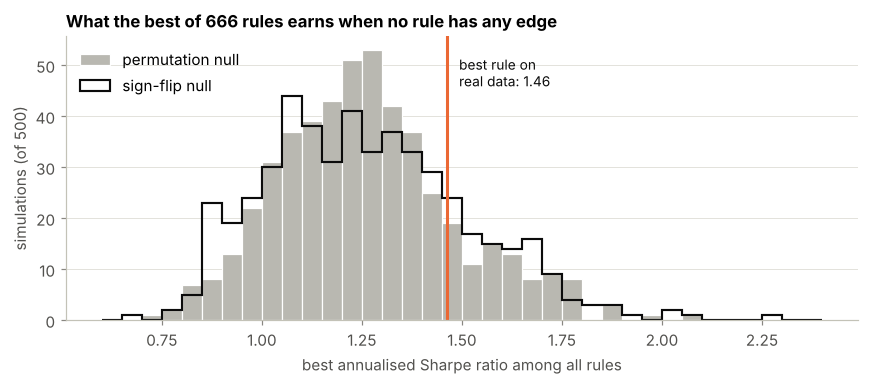

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0.6, 2.4, 37)
ax.hist(null_perm, bins=bins, color=C.NULL_GREY, edgecolor="white", linewidth=0.8,
        label="permutation null")
ax.hist(null_flip, bins=bins, histtype="step", color=C.INK, linewidth=1.4,
        label="sign-flip null")
ax.axvline(sr_real.max(), color=C.ORANGE, linewidth=2)
ax.annotate(f"best rule on\nreal data: {sr_real.max():.2f}", (sr_real.max(), ax.get_ylim()[1]*0.93),
            xytext=(8, 0), textcoords="offset points", va="top", color=C.INK, fontsize=9)
ax.set(xlabel="best annualised Sharpe ratio among all rules",
       ylabel=f"simulations (of {N_SIMS})",
       title=f"What the best of {N} rules earns when no rule has any edge")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**This is the headline number of the project.** On data where nothing is
predictable, searching these rules produces a "best strategy" with an
annualised Sharpe ratio of about 1.3 on average, and close to 1.7 one time
in twenty. A four-year backtest with a Sharpe of 1.3 is a result people
present with a straight face. Here it is the *expected* outcome of a search
that found nothing.

The two nulls agree closely, so the result does not depend on whether
volatility clustering is preserved.

## 4. Theory: the expected maximum, and how many trials there really were

The simulation can be checked against a formula. If $N$ independent strategies
all have true Sharpe zero and their *estimated* Sharpe ratios are roughly
normal with standard deviation $\sigma_{SR}$, the expected value of the best
one is (Bailey & López de Prado, 2014)

$$\mathbb{E}[\max SR] \approx \sigma_{SR}\Big[(1-\gamma)\,\Phi^{-1}\!\big(1-\tfrac1N\big) + \gamma\,\Phi^{-1}\!\big(1-\tfrac{1}{Ne}\big)\Big]$$

with $\gamma \approx 0.5772$ (Euler–Mascheroni) and $\Phi^{-1}$ the normal
quantile function. It is just the expected maximum of $N$ Gaussian draws,
scaled by how noisy one Sharpe estimate is.

The catch is the word *independent*. A 10/50 and a 10/60 moving-average
crossover are nearly the same strategy; counting them as two trials overstates
the search. This is where the internship code comes back: **effective rank**
— the entropy of the normalised spectrum, the same quantity used to ask how
many neurons' worth of independent signal a hidden layer carried — gives a
continuous estimate of how many independent strategies' worth of P&L the
rule universe contains.

In [8]:
EULER_GAMMA = 0.5772156649015329


def expected_max_sharpe(n_trials, sr_std):
    """Expected best Sharpe among n_trials zero-skill strategies (same units as sr_std)."""
    q1 = stats.norm.ppf(1 - 1 / n_trials)
    q2 = stats.norm.ppf(1 - 1 / (n_trials * math.e))
    return sr_std * ((1 - EULER_GAMMA) * q1 + EULER_GAMMA * q2)


def effective_rank(spectrum, eps=1e-12):
    """exp(Shannon entropy of the normalised spectrum) — Roy & Vetterli.

    Ported from Week_7/collapse_metrics.py. There it took singular values of an
    activation matrix; here it takes eigenvalues of a correlation matrix.
    Equals k when k values are equal and the rest are zero.
    """
    s = np.asarray(spectrum, dtype=np.float64)
    s = s[s > eps * s.max()]
    p = s / s.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


# Correlation between the rules' daily P&L, on the real data.
active = pnl.std(axis=0) > 0
corr_rules = np.corrcoef(pnl[:, active].T)
eig_rules = np.linalg.eigvalsh(corr_rules)
eig_rules = np.clip(eig_rules, 0, None)
n_eff = effective_rank(eig_rules)                       # entropy of the eigenvalues (variances)
n_eff_sv = effective_rank(np.sqrt(eig_rules))           # entropy of singular values: the Week 7 convention
print(f"{N} rules -> effective rank of their P&L correlation matrix: "
      f"{n_eff:.1f} on eigenvalues, {n_eff_sv:.1f} on singular values")

sigma_null = spread_perm.mean()            # spread of Sharpe across rules, under the null
sigma_real = sr_real.std(ddof=1)           # the same spread, on the real data
# Invert the formula: how many INDEPENDENT trials would produce the simulated maximum?
from scipy.optimize import brentq
n_implied = brentq(lambda n: expected_max_sharpe(n, sigma_null) - null_perm.mean(), 2, 1e6)

rows = [
    ("simulation (permutation null)",               null_perm.mean()),
    ("formula, N = all rules,  sigma from null",    expected_max_sharpe(N, sigma_null)),
    ("formula, N = eff. rank (singular values), sigma from null", expected_max_sharpe(n_eff_sv, sigma_null)),
    ("formula, N = eff. rank (eigenvalues),     sigma from null", expected_max_sharpe(n_eff, sigma_null)),
    ("formula, N = all rules,  sigma from real data", expected_max_sharpe(N, sigma_real)),
]
print(f"\nsigma_SR across rules:  null {sigma_null:.3f}   real data {sigma_real:.3f}\n")
print(pd.DataFrame(rows, columns=["expected best Sharpe", "value"]).to_string(index=False, float_format="%.2f"))
print(f"\nindependent trials implied by the simulation: {n_implied:.0f}  "
      f"(rules: {N}; effective rank: {n_eff:.1f} or {n_eff_sv:.1f} depending on convention)")

666 rules -> effective rank of their P&L correlation matrix: 13.6 on eigenvalues, 151.2 on singular values

sigma_SR across rules:  null 0.437   real data 0.578

                                     expected best Sharpe  value
                            simulation (permutation null)   1.26
                 formula, N = all rules,  sigma from null   1.37
formula, N = eff. rank (singular values), sigma from null   1.17
formula, N = eff. rank (eigenvalues),     sigma from null   0.75
            formula, N = all rules,  sigma from real data   1.81

independent trials implied by the simulation: 297  (rules: 666; effective rank: 13.6 or 151.2 depending on convention)


Read this table carefully, because it does not say what I expected it to.

- Counting **every rule as independent** overshoots the simulation, but only
  by about a tenth of a Sharpe point. The rules are correlated, and that is
  all the correlation is worth.
- Swapping in the **effective rank** undershoots — mildly under the
  singular-value convention used in Week 7 (151), badly under the eigenvalue
  convention (14). Inverting the formula, the simulated maximum corresponds to
  about 300 independent trials: twice one effective rank and twenty times the
  other.

So the tidy story — "the rules are highly correlated, therefore there were
really only a dozen trials" — is wrong for this purpose, and the fact that
two reasonable definitions of effective rank differ by a factor of ten is a
warning in itself (Project 2 takes that up properly). Effective rank measures
how much of the *variance* of the P&L matrix lives in a few directions. The
expected maximum depends on something else: how many near-independent draws
there are in the *tail*. A universe can have most of its variance in a dozen
directions and still contain hundreds of rules that differ enough to each
have a separate chance of getting lucky. It is the Week 7 frozen-layer lesson
again: a rank statistic describes a spectrum, and should not be used as a
stand-in for a quantity it was not built to measure.

The practical consequence: **when the null can be simulated, simulate it**,
and use the closed form as a check on the simulation rather than the other
way round.

The last row uses the spread of Sharpe ratios on the *real* data, which is
the textbook recipe for the Deflated Sharpe Ratio. That spread is about a
third wider than under the null. The gap is itself evidence: on pure noise the two
would match. Something in 2013–2018 made whole families of related rules win
or lose together. Section 5 finds out what.

## 5. The real data

First, what won.

In [9]:
order = np.argsort(sr_real)[::-1]
top = pd.DataFrame(
    [(labels[i][0], labels[i][1], labels[i][2], "mirror" if labels[i][3] < 0 else "as built",
      sr_real[i]) for i in order[:10]],
    columns=["family", "param 1", "param 2", "direction", "Sharpe"])
print(top.to_string(index=False, float_format="%.2f"))

best = order[0]
print(f"\nbest rule: {labels[best]}   Sharpe {sr_real[best]:.2f}")

family  param 1  param 2 direction  Sharpe
    ma        5       20    mirror    1.46
   mom       10        5    mirror    1.44
    ma       10       20    mirror    1.43
    ma       10       15    mirror    1.37
   mom       15        0    mirror    1.35
    ma        8       20    mirror    1.31
    ma        3       20    mirror    1.29
    ma        8       15    mirror    1.28
   brk       15        0    mirror    1.19
    ma        2       20    mirror    1.18

best rule: ('ma', 5, 20, -1)   Sharpe 1.46


The top of the table is entirely **mirrored** trend rules at 2–20 day
horizons: moving-average crossovers, momentum and breakouts, traded backwards.
A mirrored trend rule is a mean-reversion rule — sell after the market has
drifted up for a couple of weeks, buy after it has drifted down. Ten
near-neighbours winning together is exactly why the spread of Sharpe ratios
was wider than the null predicted, and it matches the sanity check earlier,
where "follow yesterday's direction" lost money. Short-horizon reversal in US
equity indices is a documented effect, so this is at least a plausible thing
to have found rather than a day-of-week curiosity.

Plausible is not the same as significant. Four tests, in increasing order of
how hard they are to fool.

### Test 1 — against the simulated null

In [10]:
def p_value(null_draws, observed):
    """One-sided Monte Carlo p-value with the +1 correction (never returns 0)."""
    return (1 + np.sum(null_draws >= observed)) / (1 + len(null_draws))


sr_best = sr_real[best]
p_perm, p_flip = p_value(null_perm, sr_best), p_value(null_flip, sr_best)
naive_p = 1 - stats.norm.cdf(sr_best / ANN * np.sqrt(T))    # as if it were the only rule tried
print(f"naive p-value (pretend only this rule was ever tested): {naive_p:.4f}")
print(f"p-value against best-of-{N}, permutation null:          {p_perm:.3f}")
print(f"p-value against best-of-{N}, sign-flip null:            {p_flip:.3f}")

naive p-value (pretend only this rule was ever tested): 0.0017
p-value against best-of-666, permutation null:          0.174
p-value against best-of-666, sign-flip null:            0.214


Tested as if it were the only idea I ever had, the best rule is significant
at the 0.2% level. Tested against what the search produces unaided, the
p-value is around 0.2: roughly one search in five over pure noise does at
least this well. Same rule, same data, same Sharpe ratio — the only thing that
changed is admitting how many things were tried.

### Test 2 — the Deflated Sharpe Ratio

The DSR (Bailey & López de Prado) packages the same correction into a formula
that needs no simulation. It is the probability that the *true* Sharpe exceeds
the expected-maximum benchmark $SR_0$, allowing for the fact that a Sharpe
estimate is noisier when returns are skewed or fat-tailed:

$$\text{DSR} = \Phi\!\left(\frac{(\widehat{SR}-SR_0)\sqrt{T-1}}{\sqrt{1-\hat\gamma_3\,\widehat{SR}+\frac{\hat\gamma_4-1}{4}\,\widehat{SR}^2}}\right)$$

where everything is in **per-day** units, $\hat\gamma_3$ is skewness and
$\hat\gamma_4$ is (non-excess) kurtosis of the strategy's returns. With
$SR_0 = 0$ this is the ordinary Probabilistic Sharpe Ratio.

In [11]:
def probabilistic_sharpe(pnl_one, sr0_annual=0.0):
    """P(true Sharpe > sr0) for one strategy, adjusting for skew and kurtosis."""
    t = len(pnl_one)
    sr = pnl_one.mean() / pnl_one.std(ddof=1)             # per-day Sharpe
    skew = stats.skew(pnl_one)
    kurt = stats.kurtosis(pnl_one, fisher=False)          # normal = 3
    denom = np.sqrt(1 - skew * sr + (kurt - 1) / 4 * sr ** 2)
    return stats.norm.cdf((sr - sr0_annual / ANN) * np.sqrt(t - 1) / denom)


best_pnl = pnl[:, best]
print(f"best rule's daily P&L: skew {stats.skew(best_pnl):+.2f}, "
      f"kurtosis {stats.kurtosis(best_pnl, fisher=False):.1f} (normal = 3)\n")

benchmarks = {
    "none (PSR: is true Sharpe > 0?)":                        0.0,
    "E[max], N = all rules, sigma from null":                 expected_max_sharpe(N, sigma_null),
    "E[max], N = all rules, sigma from real data (textbook)": expected_max_sharpe(N, sigma_real),
}
for name, sr0 in benchmarks.items():
    print(f"benchmark {sr0:4.2f}  DSR = {probabilistic_sharpe(best_pnl, sr0):.3f}   <- {name}")

best rule's daily P&L: skew +0.17, kurtosis 5.9 (normal = 3)

benchmark 0.00  DSR = 0.998   <- none (PSR: is true Sharpe > 0?)
benchmark 1.37  DSR = 0.573   <- E[max], N = all rules, sigma from null
benchmark 1.81  DSR = 0.240   <- E[max], N = all rules, sigma from real data (textbook)


A DSR is read like a confidence level: above 0.95 would be a pass. With no
correction the rule passes easily (0.999). Against the all-rules benchmark
with the null's spread it drops to about 0.57 — barely better than a coin flip
that the true Sharpe beats the selection bar. Against the textbook benchmark
(real-data spread) it falls to about a quarter. That version is conservative here,
because the real spread is inflated by the very effect being tested; the
simulation-matched one is the fairer reading, and it agrees with Test 1.

### Test 3 — White's Reality Check

The two tests above both rest on a null I built (shuffled or sign-flipped
data). The Reality Check (White, 2000) takes a different route and makes no
statement about what unpredictable returns look like. It resamples the
**strategies' own P&L** in blocks, re-centres every strategy to zero mean, and
asks how large the best one gets by resampling luck alone.

- Resampling whole **days** keeps the cross-correlation between rules intact
  (all rules are resampled with the same day indices).
- Resampling in **blocks** of random length keeps short-range time dependence
  intact — this is the *stationary bootstrap* of Politis & Romano.
- Dividing by each rule's standard deviation (Hansen's refinement) stops
  high-volatility rules from dominating the maximum, and makes the statistic a
  Sharpe ratio.

In [12]:
def stationary_bootstrap_indices(t, mean_block, rng):
    """Day indices for one stationary-bootstrap resample of length t.

    Start at a random day; each step either continues to the next day (with
    probability 1 - 1/mean_block) or jumps to a fresh random day. Block lengths
    are therefore geometric with the requested mean. Wraps around at the end.
    """
    jump = rng.random(t) < 1.0 / mean_block
    jump[0] = True
    starts = rng.integers(0, t, size=t)
    idx = np.empty(t, dtype=np.int64)
    for i in range(t):
        idx[i] = starts[i] if jump[i] else (idx[i - 1] + 1) % t
    return idx


def reality_check(pnl, n_boot=2000, mean_block=10, seed=SEED):
    """Studentised Reality Check p-value for the best column of `pnl`."""
    rng = np.random.default_rng(seed)
    t = pnl.shape[0]
    mu, sd = pnl.mean(axis=0), pnl.std(axis=0, ddof=1)
    live = sd > 0
    mu, sd, p = mu[live], sd[live], pnl[:, live]
    observed = (mu / sd).max()
    boot_max = np.empty(n_boot)
    for b in range(n_boot):
        idx = stationary_bootstrap_indices(t, mean_block, rng)
        # (resampled mean - original mean): each rule re-centred to zero skill
        boot_max[b] = ((p[idx].mean(axis=0) - mu) / sd).max()
    return p_value(boot_max, observed), boot_max * ANN


for block in (5, 10, 20):
    p_rc, rc_null = reality_check(pnl, mean_block=block)
    print(f"mean block {block:2d} days:  Reality Check p = {p_rc:.3f}   "
          f"(bootstrap best-of-{N}: mean {rc_null.mean():.2f}, 95th pct {np.quantile(rc_null, 0.95):.2f})")

mean block  5 days:  Reality Check p = 0.206   (bootstrap best-of-666: mean 1.26, 95th pct 1.75)


mean block 10 days:  Reality Check p = 0.170   (bootstrap best-of-666: mean 1.24, 95th pct 1.72)


mean block 20 days:  Reality Check p = 0.163   (bootstrap best-of-666: mean 1.21, 95th pct 1.75)


The block length is a free parameter, so it is swept rather than chosen: the
conclusion should not depend on it, and it does not. More to the point, a test
built on completely different assumptions lands in the same place as the
permutation test (p between 0.16 and 0.21), and its bootstrap "best of search"
distribution has the same centre, about 1.25, as the simulated null. Two independent routes to the same
bar is what makes the bar believable.

### Test 4 — out of sample

The least clever test and the most convincing. Pick the best rule using only
the first half of the scored period, then look at how it does in the second
half, which played no part in choosing it.

best rule in first half:  ('mom', 10, 5, -1)
  first-half Sharpe  +2.44
  second-half Sharpe +0.17   (rank 287 of 666)

full-sample winner ('ma', 5, 20, -1): first half +1.76, second half +1.10
rank correlation between halves, across rules: +0.45


  same statistic on 300 permuted series: mean -0.03, sd 0.30, 95th pct +0.47  ->  p = 0.070


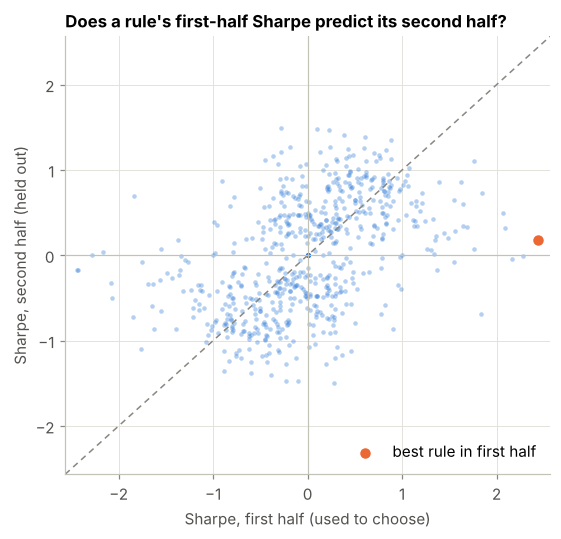

In [13]:
half = T // 2
sr_first, sr_second = sharpe(pnl[:half]), sharpe(pnl[half:])
pick = int(np.argmax(sr_first))
rho, rho_p = stats.spearmanr(sr_first[:N//2], sr_second[:N//2])   # unmirrored half only

print(f"best rule in first half:  {labels[pick]}")
print(f"  first-half Sharpe  {sr_first[pick]:+.2f}")
print(f"  second-half Sharpe {sr_second[pick]:+.2f}   "
      f"(rank {int((sr_second > sr_second[pick]).sum()) + 1} of {N})")
print(f"\nfull-sample winner {labels[best]}: first half {sr_first[best]:+.2f}, second half {sr_second[best]:+.2f}")
print(f"rank correlation between halves, across rules: {rho:+.2f}")

# The rules are heavily correlated with each other, so the textbook p-value for
# that rank correlation (which assumes independent points) is meaningless.
# Calibrate it the honest way: the same statistic on series with no signal.
rng = np.random.default_rng(SEED + 3)
rho_null = np.empty(300)
for i in range(len(rho_null)):
    fake = rng.permutation(r)
    sig, _ = make_signals(fake, weekday)
    f_pnl = backtest(fake, sig)
    rho_null[i] = stats.spearmanr(sharpe(f_pnl[:half])[:N//2], sharpe(f_pnl[half:])[:N//2])[0]
p_rho = p_value(rho_null, rho)
print(f"  same statistic on {len(rho_null)} permuted series: mean {rho_null.mean():+.2f}, "
      f"sd {rho_null.std(ddof=1):.2f}, 95th pct {np.quantile(rho_null, 0.95):+.2f}  ->  p = {p_rho:.3f}")

fig, ax = plt.subplots(figsize=(5.2, 5))
fam = np.array([l[0] for l in labels])
ax.scatter(sr_first, sr_second, s=9, color=C.BLUE, alpha=0.35, linewidths=0)
ax.scatter(sr_first[pick], sr_second[pick], s=70, color=C.ORANGE, edgecolor="white",
           linewidth=1.5, zorder=3, label="best rule in first half")
lim = 1.05 * max(np.abs(sr_first).max(), np.abs(sr_second).max())
ax.plot([-lim, lim], [-lim, lim], color=C.MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.axhline(0, color="#c3c2b7", linewidth=0.8); ax.axvline(0, color="#c3c2b7", linewidth=0.8)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="Sharpe, first half (used to choose)",
       ylabel="Sharpe, second half (held out)", title="Does a rule's first-half Sharpe predict its second half?")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Each dot is one rule. If first-half performance carried over perfectly the
cloud would lie along the dashed diagonal. (The mirror construction makes the
picture point-symmetric about the origin, so the rank correlation is computed
on the un-mirrored half only.)

Two different things are visible, and they should be kept apart.

**The winner did not survive.** The best rule of the first half had a Sharpe
of 2.4 there and 0.2 afterwards, landing in the middle of the pack. Selecting
the top rule bought essentially nothing.

**The ordering as a whole partly did.** Across all rules the rank correlation
between halves is +0.45: rules that did well early tended to do well late,
and the full-sample winner was positive in both halves. But note what the
calibration says. Because the rules are so correlated with one another, that
statistic has a standard deviation of 0.3 on pure noise, and +0.45 is reached
by chance about 7% of the time. It looks like a strong correlation in the
scatter and it is a borderline one.

This is the family-level effect again — reversal beat trend in both halves —
and it is suggestive rather than established.

## 6. Probability of Backtest Overfitting

A single split is one draw. *Combinatorially symmetric cross-validation*
(Bailey, Borwein, López de Prado & Zhu) repeats the experiment over every way
of dividing the sample into two halves made of whole blocks:

1. Cut the scored period into $S = 16$ consecutive blocks.
2. For each of the $\binom{16}{8} = 12{,}870$ ways to choose 8 blocks as
   in-sample: find the best rule in-sample, then find its **rank** among all
   rules on the other 8 blocks.
3. **PBO** = the fraction of splits in which the in-sample winner lands in the
   bottom half out-of-sample.

PBO near 0 means selection works; near 0.5 means choosing the in-sample winner
is no better than choosing at random; above 0.5 means it is actively harmful.

The implementation avoids touching the raw P&L 12,870 times. A Sharpe ratio
only needs a sum and a sum of squares, and both add across blocks, so they are
computed once per block and each split is then a cheap matrix product.

In [14]:
def cscv_pbo(pnl, n_blocks=16):
    """Probability of backtest overfitting via CSCV.

    Returns (pbo, oos_rank_of_is_winner, is_sharpe_of_winner, oos_sharpe_of_winner),
    the last three with one entry per split.
    """
    t, n = pnl.shape
    size = t // n_blocks
    blocks = pnl[: size * n_blocks].reshape(n_blocks, size, n)
    s1 = blocks.sum(axis=1)                  # (blocks, rules): sum of P&L
    s2 = (blocks ** 2).sum(axis=1)           #                  sum of squares

    combos = np.array(list(itertools.combinations(range(n_blocks), n_blocks // 2)))
    member = np.zeros((len(combos), n_blocks))
    member[np.arange(len(combos))[:, None], combos] = 1.0      # 1 = in-sample block

    def sharpe_from_sums(mask):
        m = mask.sum(axis=1, keepdims=True) * size             # days in this half
        mean = mask @ s1 / m
        var = (mask @ s2 / m - mean ** 2) * m / (m - 1)
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.where(var > 0, mean / np.sqrt(var), 0.0) * ANN

    sr_is, sr_oos = sharpe_from_sums(member), sharpe_from_sums(1.0 - member)
    winner = sr_is.argmax(axis=1)
    rows = np.arange(len(combos))
    win_oos = sr_oos[rows, winner]
    # relative rank in (0, 1): share of rules the in-sample winner beats out-of-sample
    rel_rank = (sr_oos < win_oos[:, None]).sum(axis=1) / (n - 1)
    return float((rel_rank < 0.5).mean()), rel_rank, sr_is[rows, winner], win_oos


pbo, rel_rank, win_is, win_oos = cscv_pbo(pnl)
print(f"splits: {len(rel_rank):,}")
print(f"PBO = {pbo:.2f}")
print(f"in-sample winner:  mean in-sample Sharpe {win_is.mean():.2f}  ->  "
      f"mean out-of-sample Sharpe {win_oos.mean():+.2f}")
print(f"out-of-sample Sharpe of the in-sample winner is negative in {np.mean(win_oos < 0):.0%} of splits")

# calibration: the same procedure on data with no signal should give PBO ~ 0.5
rng = np.random.default_rng(SEED + 1)
pbo_null = np.empty(100)
for i in range(len(pbo_null)):
    fake = rng.permutation(r)
    sig, _ = make_signals(fake, weekday)
    pbo_null[i] = cscv_pbo(backtest(fake, sig))[0]
p_pbo = (1 + np.sum(pbo_null <= pbo)) / (1 + len(pbo_null))
print(f"\ncalibration, {len(pbo_null)} permuted series: PBO mean {pbo_null.mean():.2f}, "
      f"sd {pbo_null.std(ddof=1):.2f}, 5th pct {np.quantile(pbo_null, 0.05):.2f}")
print(f"share of no-signal series with PBO at or below the real one: {p_pbo:.2f}")

splits: 12,870
PBO = 0.28
in-sample winner:  mean in-sample Sharpe 1.98  ->  mean out-of-sample Sharpe +0.32
out-of-sample Sharpe of the in-sample winner is negative in 28% of splits



calibration, 100 permuted series: PBO mean 0.51, sd 0.19, 5th pct 0.19
share of no-signal series with PBO at or below the real one: 0.16


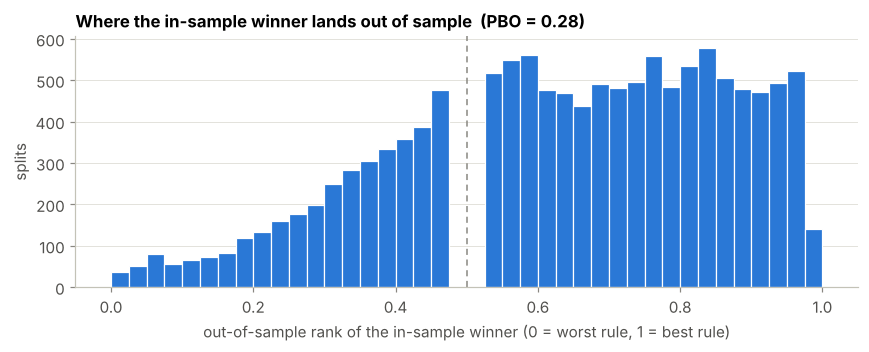

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(rel_rank, bins=40, range=(0, 1), color=C.BLUE, edgecolor="white", linewidth=0.8)
ax.axvline(0.5, color=C.MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.set(xlabel="out-of-sample rank of the in-sample winner (0 = worst rule, 1 = best rule)",
       ylabel="splits", title=f"Where the in-sample winner lands out of sample  (PBO = {pbo:.2f})")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

(The empty bin just above 0.5 is not a plotting fault. Rules that do not trade
in a given out-of-sample half score exactly zero there, and with mirrors the
median is zero too, so a block of tied rules sits in the middle of the ranking
and no winner can land inside it.)

**The number to remember is the haircut.** Averaged over 12,870 splits, the
in-sample winner has a Sharpe of about 2.0 in-sample and about 0.3
out-of-sample. Roughly 85% of the selected Sharpe ratio is selection.

**The PBO itself is 0.28**, below the 0.5 that "no information" would give.
The calibration is what stops that being over-read: on series with no signal
at all, PBO averages 0.51 as it should, but with a standard deviation of 0.19
— and 16% of pure-noise series produce a PBO as low as the real one. A single
PBO from four years of data is a noisy statistic. It leans the same way as
every other test here and is no more decisive than they are.

## 7. The same disease in ML form: purged and embargoed cross-validation

Everything so far concerned rule-based strategies. Fit a machine-learning
model to predict returns and a second, quieter leak appears, and this one is
in the cross-validation itself.

The usual target is a **forward return over several days**: the label for day
$t$ is the return from $t$ to $t+20$. Labels for neighbouring days therefore
overlap — day $t$ and day $t+1$ share 19 of their 20 days. Standard k-fold
with shuffling scatters neighbours across train and test, so for almost every
test point the model has seen a training point with *nearly the same label*
and nearly the same features. A flexible model only has to learn "what
happened around here" to score well. It has learned nothing about the future.

The fix (López de Prado, *Advances in Financial ML*, ch. 7) has two parts:

- **Purging**: test folds are contiguous blocks of time, and any training
  sample whose label window overlaps the test block is deleted.
- **Embargo**: a further gap is left *after* the test block, because features
  built from rolling windows carry information forward across the boundary.

To make the leak undeniable the experiment below is run on **shuffled market
returns**, where the true predictive power of any feature is exactly zero. Any
score above zero is leakage, by construction.

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

HORIZON = 20       # label: return over the next 20 days


def make_ml_dataset(ret):
    """Slow-moving features and an overlapping forward-return label."""
    logp = np.cumsum(np.log1p(ret))
    feats = np.column_stack([
        rolling_std(ret, 20), rolling_std(ret, 60),          # volatility
        logp - rolling_mean(logp, 20),                        # distance from 20d mean
        logp - rolling_mean(logp, 60),                        # distance from 60d mean
        rolling_mean(ret, 60),                                # 60d drift
    ])
    fwd = np.full(len(ret), np.nan)
    fwd[:-HORIZON] = logp[HORIZON:] - logp[:-HORIZON]         # return from t to t+20
    keep = ~np.isnan(feats).any(axis=1) & ~np.isnan(fwd)
    return feats[keep], fwd[keep]


class PurgedKFold:
    """K contiguous test blocks; training samples that could leak are removed.

    For a test block [a, b):
      purge   - drop training samples in [a - horizon, a): their label window
                reaches into the test block.
      embargo - drop training samples in [b, b + horizon + embargo): the test
                labels reach `horizon` days past b, and rolling features carry
                test-period information a little further still.
    """

    def __init__(self, n_splits=5, horizon=HORIZON, embargo=0):
        self.n_splits, self.horizon, self.embargo = n_splits, horizon, embargo

    def split(self, X):
        n = len(X)
        edges = np.linspace(0, n, self.n_splits + 1).astype(int)
        for a, b in zip(edges[:-1], edges[1:]):
            idx = np.arange(n)
            train = (idx < a - self.horizon) | (idx >= b + self.horizon + self.embargo)
            yield idx[train], idx[a:b]


def cv_information_coefficient(X, y, splitter):
    """Mean out-of-fold rank correlation between prediction and label (the 'IC')."""
    ics = []
    for tr, te in splitter.split(X):
        model = RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                      n_jobs=-1, random_state=0).fit(X[tr], y[tr])
        ics.append(stats.spearmanr(model.predict(X[te]), y[te])[0])
    return float(np.mean(ics))


schemes = {
    "shuffled k-fold":             lambda: KFold(5, shuffle=True, random_state=0),
    "contiguous k-fold, no purge": lambda: KFold(5, shuffle=False),
    "purged k-fold":               lambda: PurgedKFold(5, embargo=0),
    "purged + 60-day embargo":     lambda: PurgedKFold(5, embargo=60),
}

rng = np.random.default_rng(SEED + 2)
N_SEEDS = 30
scores = {name: [] for name in schemes}
for _ in range(N_SEEDS):
    X, y = make_ml_dataset(rng.permutation(r))        # NO true signal
    for name, make in schemes.items():
        scores[name].append(cv_information_coefficient(X, y, make()))

cv_table = pd.DataFrame({
    "mean IC": {k: np.mean(v) for k, v in scores.items()},
    "SEM":     {k: np.std(v, ddof=1) / np.sqrt(N_SEEDS) for k, v in scores.items()},
})
print(f"random forest on data with ZERO true signal ({N_SEEDS} seeds, {len(y)} samples each)\n")
print(cv_table.to_string(float_format="%+.3f"))

# paired: both schemes scored the SAME noise series, so test the per-seed difference
diff = np.array(scores["contiguous k-fold, no purge"]) - np.array(scores["purged k-fold"])
print(f"\ncontiguous minus purged, paired over seeds: {diff.mean():+.3f} "
      f"+/- {diff.std(ddof=1)/np.sqrt(N_SEEDS):.3f} (SEM)")

random forest on data with ZERO true signal (30 seeds, 1179 samples each)

                             mean IC    SEM
shuffled k-fold               +0.744 +0.005
contiguous k-fold, no purge   +0.035 +0.022
purged k-fold                 +0.015 +0.023
purged + 60-day embargo       +0.014 +0.023

contiguous minus purged, paired over seeds: +0.020 +/- 0.004 (SEM)


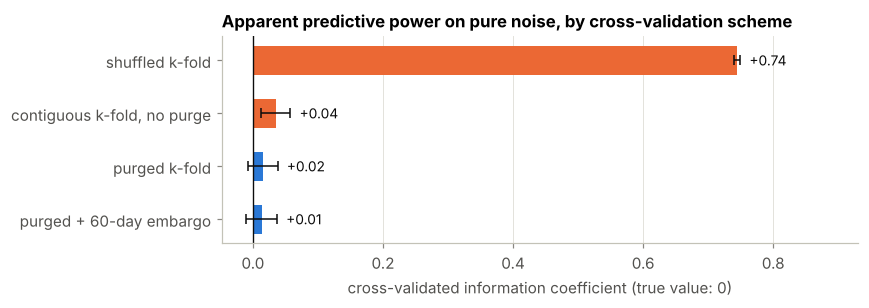

In [17]:
fig, ax = plt.subplots(figsize=(8, 2.9))
names = list(schemes)[::-1]
means = cv_table.loc[names, "mean IC"].to_numpy()
sems = cv_table.loc[names, "SEM"].to_numpy()
ax.barh(names, means, height=0.55, color=[C.BLUE if "purged" in n else C.ORANGE for n in names],
        xerr=sems, error_kw=dict(ecolor=C.INK, elinewidth=1, capsize=3))
ax.axvline(0, color=C.INK, linewidth=0.9)
for yi, m in enumerate(means):
    ax.annotate(f"{m:+.2f}", (max(m, 0) + sems[yi], yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=C.INK)
ax.set(xlabel="cross-validated information coefficient (true value: 0)",
       title="Apparent predictive power on pure noise, by cross-validation scheme")
ax.set_xlim(right=means.max() * 1.25)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

For scale: in real return prediction an information coefficient of 0.02–0.05
is a good signal.

**Shuffling is catastrophic.** A random forest achieves an IC of 0.74 on data
with no signal in it. Nothing about the code is wrong and nothing would warn
you; the cross-validation scheme simply does not match the structure of the
data. This is the single most common way an ML return-prediction result turns
out to be nothing.

**Contiguous folds remove almost all of it**, because neighbours now stay on
the same side of the split except at the fold boundaries.

**Purging removes what is left at the boundaries.** The bars for the last
three schemes overlap, but the comparison is paired — each seed's noise series
was scored under every scheme — and on the paired differences purging lowers
the IC by 0.020 ± 0.004. That is five standard errors, and it is the same size
as a genuinely useful signal. An unpurged backtest of a real 0.02-IC signal
would report it as roughly double.

**The embargo adds nothing measurable here.** That is an honest null: these
features have at most a 60-day memory and the purge is already 20 days wide
on each side. It would matter more with longer-memory features.

After purging, the mean IC is +0.015 ± 0.023, which is zero to within the
noise — the right answer for data with nothing in it.

## 8. What was found

Every number in the table is computed by the cell, not typed.

In [18]:
p_rc10, _ = reality_check(pnl, mean_block=10)
summary = pd.DataFrame([
    ("rules searched (incl. mirrors)",                              f"{N}"),
    ("years of data scored",                                        f"{T/252:.1f}"),
    ("best-of-search Sharpe on pure noise, mean",                   f"{null_perm.mean():.2f}"),
    ("best-of-search Sharpe on pure noise, 95th percentile",        f"{np.quantile(null_perm, 0.95):.2f}"),
    ("best rule on real data",                                      f"{labels[best]}"),
    ("its Sharpe",                                                  f"{sr_best:.2f}"),
    ("naive p-value (as if the only rule tried)",                   f"{naive_p:.4f}"),
    ("p-value vs permutation null",                                 f"{p_perm:.3f}"),
    ("p-value vs sign-flip null",                                   f"{p_flip:.3f}"),
    ("Reality Check p-value (10-day blocks)",                       f"{p_rc10:.3f}"),
    ("Deflated Sharpe Ratio (benchmark matched to simulation)",     f"{probabilistic_sharpe(best_pnl, expected_max_sharpe(N, sigma_null)):.2f}"),
    ("first-half winner's second-half Sharpe",                      f"{sr_second[pick]:+.2f}"),
    ("rank correlation of rule Sharpe, first vs second half",       f"{rho:+.2f}  (p = {p_rho:.2f} vs null)"),
    ("Probability of Backtest Overfitting",                         f"{pbo:.2f}  (null: {pbo_null.mean():.2f} +/- {pbo_null.std(ddof=1):.2f} sd)"),
    ("IC on pure noise, shuffled k-fold",                           f"{cv_table.loc['shuffled k-fold', 'mean IC']:+.2f}"),
    ("IC on pure noise, purged + embargoed",                        f"{cv_table.loc['purged + 60-day embargo', 'mean IC']:+.2f}"),
], columns=["quantity", "value"])
print(summary.to_string(index=False))

                                               quantity                          value
                         rules searched (incl. mirrors)                            666
                                   years of data scored                            4.0
              best-of-search Sharpe on pure noise, mean                           1.26
   best-of-search Sharpe on pure noise, 95th percentile                           1.68
                                 best rule on real data              ('ma', 5, 20, -1)
                                             its Sharpe                           1.46
              naive p-value (as if the only rule tried)                         0.0017
                            p-value vs permutation null                          0.174
                              p-value vs sign-flip null                          0.214
                  Reality Check p-value (10-day blocks)                          0.170
Deflated Sharpe Ratio (benchmark matched to

### What this establishes

1. **The noise floor is high.** A search over 666 simple rules on four years
   of daily data yields a best Sharpe of about 1.26 on average when nothing is
   predictable, and 1.68 at the 95th percentile. Two differently constructed
   nulls and a bootstrap that uses neither agree on this to within a few
   hundredths.
2. **The best real rule does not clear it.** Its Sharpe of 1.46 has a naive
   p-value of 0.002 and a search-corrected p-value of about 0.2, by three
   methods resting on different assumptions.
3. **Selection costs about 85% of the apparent Sharpe.** In-sample winners
   average 2.0 in-sample and 0.3 out-of-sample.
4. **There is a hint of something real at the family level.** Short-horizon
   reversal rules won together, in both halves, and the cross-rule dispersion
   is a third wider than noise predicts. None of the tests for it reaches
   conventional significance (p between 0.07 and 0.2). The right description
   is "worth a properly designed follow-up", not "found".
5. **Shuffled cross-validation on overlapping labels manufactures an IC of
   0.74 from pure noise.** Contiguous folds remove almost all of it, and
   purging removes a further 0.020 ± 0.004 — small in absolute terms, and as
   large as a real signal.
6. **Effective rank is the wrong tool for counting trials.** The search
   behaved like about 300 independent trials; the effective rank of the P&L
   correlation matrix says 151 or 14 depending on the convention.

### What it does not establish

- **Four years, one market, one regime.** 2013–2018 was a low-volatility bull
  market. The size of the noise floor scales roughly with $1/\sqrt{\text{years}}$,
  so on twenty years of data it would be less than half as high.
- **Survivorship bias** in the stock universe behind the index. Demeaning
  removes its effect on the average return but not on anything else.
- **No transaction costs.** `backtest` accepts `cost_bps` and it was left at
  zero, because costs are irrelevant to the null. They are not irrelevant to
  the real rule: fast reversal rules trade often, and finding 4 should be
  re-examined net of costs before anyone gets attached to it.
- **The rule universe is mine.** A different researcher's 666 rules would
  give a different floor. The method transfers; the number does not.
- **A non-significant result is not evidence of absence.** With four years
  of data, a true Sharpe of 0.5 would be nearly undetectable after this much
  searching. The test has low power and says so.

### Where to take it next

1. **Pre-register the family-level hypothesis.** Finding 4 was noticed after
   looking. The clean test is to state "mirrored trend rules at 5–20 days"
   *before* touching a second dataset (another index, or 2018 onwards) and
   test that one hypothesis there, with no search and therefore no correction.
2. **Power analysis.** Plant a known signal of Sharpe 0.3, 0.5, 1.0 in the
   permuted data and measure how often each test detects it. That turns "not
   significant" into "could have detected an effect of at least X".
3. **Cluster the rules** (López de Prado's ONC method) to estimate the number
   of independent trials properly, and compare against the ~300 implied here.
4. **Costs**, then **longer survivorship-free data** via WRDS/CRSP.

### References

- Bailey & López de Prado (2014), *The Deflated Sharpe Ratio*, Journal of Portfolio Management.
- Bailey, Borwein, López de Prado & Zhu (2017), *The probability of backtest overfitting*, Journal of Computational Finance.
- White (2000), *A reality check for data snooping*, Econometrica.
- Hansen (2005), *A test for superior predictive ability*, Journal of Business & Economic Statistics.
- Politis & Romano (1994), *The stationary bootstrap*, Journal of the American Statistical Association.
- Sullivan, Timmermann & White (1999), *Data-snooping, technical trading rule performance, and the bootstrap*, Journal of Finance.
- López de Prado (2018), *Advances in Financial Machine Learning*, ch. 7 (purged k-fold) and ch. 11–14.